# Explore: 2023 Qatar GP

Loads the cached OpenF1 JSON (run `replay/fetch_openf1.py` first) and looks at fields, sampling rates, and lap times for every driver before designing the replay/metrics schema.

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path('../data')
session_dirs = sorted(DATA_DIR.glob('*'))
session_dirs = [d for d in session_dirs if d.is_dir()]
print('Cached sessions:', [d.name for d in session_dirs])
SESSION_KEY = session_dirs[-1].name if session_dirs else None
SESSION_KEY

Cached sessions: ['9221']


'9221'

In [2]:
session_dir = DATA_DIR / SESSION_KEY

def load(endpoint):
    with open(session_dir / f'{endpoint}.json') as f:
        return pd.DataFrame(json.load(f))

def load_per_driver(endpoint, driver_number):
    with open(session_dir / endpoint / f'{driver_number}.json') as f:
        return pd.DataFrame(json.load(f))

drivers = load('drivers')
laps = load('laps')
stints = load('stints')
pit = load('pit')
race_control = load('race_control')
intervals = load('intervals')
position = load('position')

# car_data and location are cached per driver (too large for one request); load one driver as a sample
sample_driver = int(drivers['driver_number'].iloc[0])
car_data = load_per_driver('car_data', sample_driver)
location = load_per_driver('location', sample_driver)

for name, df in [('drivers', drivers), ('laps', laps), ('stints', stints), ('pit', pit),
                  ('race_control', race_control), ('intervals', intervals),
                  ('position', position),
                  (f'car_data (driver {sample_driver})', car_data),
                  (f'location (driver {sample_driver})', location)]:
    print(f'{name}: {len(df)} rows, columns = {list(df.columns)}')

drivers: 20 rows, columns = ['meeting_key', 'session_key', 'driver_number', 'broadcast_name', 'full_name', 'name_acronym', 'team_name', 'team_colour', 'first_name', 'last_name', 'headshot_url', 'country_code']
laps: 1009 rows, columns = ['meeting_key', 'session_key', 'driver_number', 'lap_number', 'date_start', 'duration_sector_1', 'duration_sector_2', 'duration_sector_3', 'i1_speed', 'i2_speed', 'is_pit_out_lap', 'lap_duration', 'segments_sector_1', 'segments_sector_2', 'segments_sector_3', 'st_speed']
stints: 73 rows, columns = ['meeting_key', 'session_key', 'stint_number', 'driver_number', 'lap_start', 'lap_end', 'compound', 'tyre_age_at_start']
pit: 54 rows, columns = ['date', 'session_key', 'pit_duration', 'lap_number', 'meeting_key', 'driver_number', 'lane_duration', 'stop_duration']
race_control: 137 rows, columns = ['meeting_key', 'session_key', 'date', 'driver_number', 'lap_number', 'category', 'flag', 'scope', 'sector', 'qualifying_phase', 'message']
intervals: 21809 rows, co

## Sampling rates

`car_data` and `location` are high-frequency telemetry; check the real interval before deciding what to turn into metrics vs. spans.

In [3]:
for name, df in [('car_data', car_data), ('location', location), ('position', position), ('intervals', intervals)]:
    if 'date' in df.columns and len(df) > 1:
        ts = pd.to_datetime(df['date'], format='ISO8601').sort_values()
        deltas = ts.diff().dt.total_seconds().dropna()
        print(f'{name}: median interval ~{deltas.median():.3f}s, n={len(df)}')

car_data: median interval ~0.240s, n=35199
location: median interval ~0.240s, n=35801
position: median interval ~0.000s, n=1058
intervals: median interval ~0.172s, n=21809


## Lap times for every driver

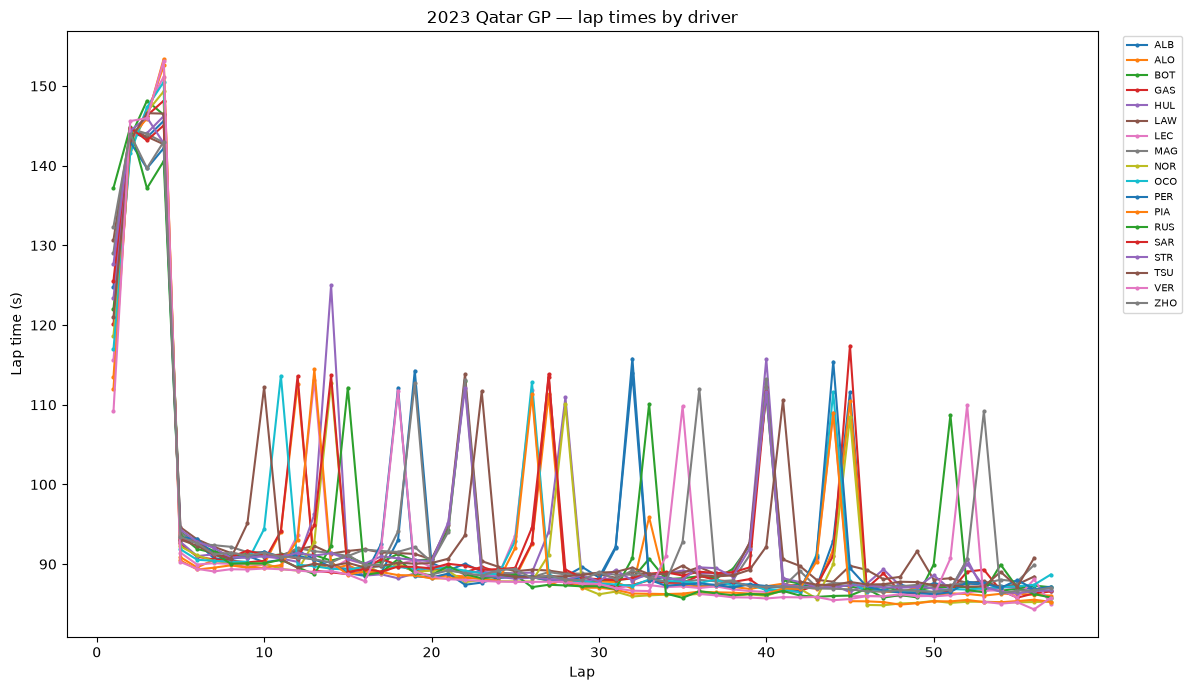

In [4]:
driver_name = dict(zip(drivers['driver_number'], drivers['name_acronym']))
laps = laps.dropna(subset=['lap_duration'])
laps['driver'] = laps['driver_number'].map(driver_name)

fig, ax = plt.subplots(figsize=(12, 7))
for driver, group in laps.groupby('driver'):
    ax.plot(group['lap_number'], group['lap_duration'], marker='o', markersize=2, label=driver)

ax.set_xlabel('Lap')
ax.set_ylabel('Lap time (s)')
ax.set_title('2023 Qatar GP — lap times by driver')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=7, ncol=1)
plt.tight_layout()
plt.show()

## Race control messages (candidate incident annotations)

In [5]:
race_control[['date', 'category', 'message']].sort_values('date')

,date,category,message
0,2023-10-08T16:10:00+00:00,Flag,GREEN LIGHT - PIT EXIT OPEN
1,2023-10-08T16:20:01+00:00,Other,PIT EXIT CLOSED
2,2023-10-08T16:45:12+00:00,Other,RISK OF RAIN FOR F1 RACE IS 0%
3,2023-10-08T16:57:08+00:00,Drs,DRS DISABLED
4,2023-10-08T17:03:33.775000+00:00,SessionStatus,SESSION STARTED
...,...,...,...
132,2023-10-08T18:31:13.138000+00:00,SessionStatus,SESSION FINISHED
133,2023-10-08T18:31:15+00:00,Flag,CHEQUERED FLAG
134,2023-10-08T18:33:27+00:00,Other,CAR 27 (HUL) TIME 1:26.444 DELETED - TRACK LIM...
135,2023-10-08T18:36:17+00:00,Other,FIA STEWARDS: INCIDENT INVOLVING CAR 11 (PER) ...
